# 07 · Propuesta final y competencia de modelos
Este notebook (1) fija la propuesta final con lo que se alcanzó a probar en los notebooks 06 y 06b, (2) la pone a competir contra otros modelos con las mismas reglas y (3) argumenta por qué la métrica principal es WAPE y no otra. No modifica el 06 ni el 06b.

## 1. Propuesta final
**Modelo:** LightGBM global sobre `log(amount_total)` diario, horizonte directo de 14 días, con las 30 features y los hiperparámetros de referencia del 06, **más la capa de reinicio de régimen** (V1b del 06b, código en `src/models/regime.py`).

| Decisión | Qué se hace | Por qué (evidencia) |
|---|---|---|
| Modelo base | LightGBM, objetivo L2 en log, 30 features | 06: WAPE 7.5 % contra 8.2 % de `sma4` en regulares; ninguna ablación ni hiperparámetro superó la regla de 0.2 pts |
| Capa de reinicio | Tras la temporada alta, el pronóstico se reescala con `sma4 limpio / sma4`; fin de régimen el 31-dic | 06b: post-Navidad de 57.9 % a 12.8 % de WAPE, regulares sin cambio (−0.00 pts) |
| Ventanas | Buen Fin −21/+20 días, Navidad −17/+14 (referencia) y −17/+6 (destino) | 06b §6.1: no deben dejar huecos entre ellas; se conservan las de la Fase 2 |
| Target multiplicativo (V2) | **No se adopta** | −0.17 pts en desarrollo contra los 0.2 requeridos; no toca post-Navidad ni los picos |
| Cuantiles p10/p90 | **Pendiente** | Sin ellos, el pico del Buen Fin (−59 %) y la rampa navideña (−20 % y −32 %) quedan sin cuantificar |

**Uso recomendado:** pronóstico de línea base en semanas sin eventos y reinicio automático al terminar la temporada alta; en ventanas de Buen Fin y Navidad se emite con alerta explícita y revisión humana, porque ningún modelo prueba que acierte la magnitud de un evento del que solo hay una ocurrencia.

**Límites que se mantienen:** cada evento aparece una sola vez; el reinicio se diagnosticó sobre el mismo fold donde se mide; el sobrepronóstico de enero (+10 % a +14 %) queda sin explicar del todo (ancla de octubre y features contaminadas).

## 2. Protocolo de la competencia (fijado antes de ejecutar)
**Mismas reglas para todos.** Los 14 folds del backtest continuo (48 semanas, 06b §1), horizonte de 14 días, reentrenamiento por fold con fechas ≤ inicio − 14. Los modelos de ML reciben las mismas 30 features y el mismo objetivo `log(y)`. Cada competidor recibe una rejilla pequeña de hiperparámetros evaluada **solo en los folds de desarrollo** (la misma regla que se usó con LightGBM); confirmación, eventos y folds extra solo se reportan.

**Competidores**
- Baselines: `sma4`, `snaive` (mismo día de hace 14 días), `ma28`.
- Estadístico: ETS por serie (Holt-Winters aditivo en log, tendencia amortiguada, estacionalidad semanal). Usa solo la historia de la propia serie.
- ML global: Ridge (lineal, con dummies de día de la semana), Random Forest y XGBoost.
- LightGBM del 06, solo y con la capa de reinicio (propuesta final).

**La capa de reinicio no es exclusiva de nuestro modelo.** Para no comparar «nuestro modelo + capa» contra competidores sin ella, la competencia se reporta en dos universos: sin capa para nadie y con la misma capa aplicada a todos. La capa es un factor multiplicativo que depende solo de calendario y de historia con ≥ 14 días de rezago, así que se puede aplicar a cualquier pronóstico.

**Criterios para afirmar que la propuesta es la mejor** (se evalúan en la sección 7):
- **K1, regulares (9 folds, 33 semanas):** el WAPE medio de la propuesta no supera en más de 0.1 pts al del mejor competidor, y **ningún competidor la supera con significancia** (el IC95 bootstrap por semanas de Δ = WAPE propuesta − WAPE competidor no puede quedar por completo por encima de 0). Ganar con significancia a un competidor es un resultado adicional; con las semanas disponibles es probable que haya empates técnicos entre modelos de la misma familia.
- **K2, post-evento:** con la misma capa para todos, la propuesta queda entre los dos mejores en `post_navidad_2024`.
- **K3, eventos (Buen Fin, Navidad y sus semanas previas):** no se exige ganar. Cada evento ocurre una vez, así que se reportan sin usarlos para elegir.
- **K4, empates:** si otro modelo empata técnicamente, no hay ganador estadístico. La elección se justifica por criterios secundarios declarados: tiempo de cómputo, interpretabilidad y estabilidad entre folds.

In [1]:
import sys, os, time, json; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%config InlineBackend.figure_format = 'retina'
from scipy import stats

from src.data.load import load_transactions, load_stores, load_calendar
from src.data.preprocess import build_panel
from src.features.engineering import FeatureConfig, build_features
from src.models.backtest import add_week
from src.models.significance import compare
from src.models.folds_continuous import ALL_FOLDS, OFFICIAL
from src.models import train as T, competitors as C, regime as R
plt.rcParams.update({'figure.figsize': (10, 3.8), 'axes.grid': True, 'grid.alpha': .3, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 180, 'display.max_columns', 40, 'display.float_format', '{:,.2f}'.format)
KEY = ['store_id', 'category', 'date']
p = build_panel(load_transactions(), load_stores(), load_calendar())
cfg = FeatureConfig(horizon=14); cols = cfg.feature_columns(); P0 = dict(T.DEFAULT_PARAMS); F = build_features(p, cfg)
print(len(cols), 'features |', len(ALL_FOLDS), 'folds continuos |', ALL_FOLDS[0].start, '→', ALL_FOLDS[-1].end)

30 features | 14 folds continuos | 2023-03-27 → 2024-02-25


## 3. Predicciones de todos los modelos

In [2]:
CACHE = '/tmp/cache07'; os.makedirs(CACHE, exist_ok=True); TF = f'{CACHE}/times.json'
TIMES = json.load(open(TF)) if os.path.exists(TF) else {}
def cached(name, fn):
    f = f'{CACHE}/{name}.parquet'
    if os.path.exists(f): return pd.read_parquet(f)
    t0 = time.time(); d = fn(); TIMES[name] = time.time() - t0; json.dump(TIMES, open(TF, 'w')); d.to_parquet(f, index=False); print(f'{name}: {TIMES[name]:.0f} s'); return d

dev = [f for f in ALL_FOLDS if f.name in T.DEV_FOLDS]; HP, TUNING = {}, {}
for n in ('ridge', 'xgb', 'rf'):
    def _tune(n=n):
        hp, t = C.tune_on_dev(F, 14, cols, n, dev); t['elegido'] = [all(np.isclose(r[k], v) for k, v in hp.items()) for _, r in t.iterrows()]; return t
    t = cached(f'tune_{n}', _tune); TUNING[n] = t; HP[n] = {k: (int(v) if k in ('max_depth', 'min_samples_leaf') else float(v)) for k, v in t[t.elegido].iloc[0].drop(['WAPE desarrollo %', 'elegido']).items()}
print('Hiperparámetros elegidos en desarrollo:', HP)
pd.concat({n: TUNING[n].drop(columns='elegido') for n in TUNING}).round(2)

Hiperparámetros elegidos en desarrollo: {'ridge': {'alpha': 1.0}, 'xgb': {'max_depth': 6}, 'rf': {'min_samples_leaf': 10}}


alpha  WAPE desarrollo %  max_depth  min_samples_leaf
ridge 0   1.00               7.17        NaN               NaN
      1  10.00               7.17        NaN               NaN
      2 100.00               7.20        NaN               NaN
xgb   0    NaN               7.63       4.00               NaN
      1    NaN               7.62       6.00               NaN
      2    NaN               7.66       8.00               NaN
rf    0    NaN               7.63        NaN             10.00
      1    NaN               7.96        NaN             50.00

In [3]:
t0 = time.time(); ref = T.run_backtest(F, cfg, P0, cols, ALL_FOLDS).rename(columns={'pred': 'pred_lgbm'}); TIMES['pred_lgbm'] = time.time() - t0
P = ref
for n in ('ridge', 'xgb', 'rf'):
    P = P.merge(cached(f'pred_{n}', lambda n=n: C.run_backtest_model(F, 14, cols, ALL_FOLDS, n, **HP[n])).drop(columns='fold'), on=KEY, how='left')
P = P.merge(cached('pred_ets', lambda: C.run_ets(F, 14, ALL_FOLDS)).drop(columns='fold'), on=KEY, how='left')
fac = F[KEY].assign(fac=R.final_factor(F)); P = P.merge(fac, on=KEY, how='left')
MODELS = {'sma4': 'base_sma4', 'snaive (14 d)': 'base_snaive', 'ma28': 'base_ma28', 'ETS por serie': 'pred_ets', 'Ridge': 'pred_ridge', 'Random Forest': 'pred_rf', 'XGBoost': 'pred_xgb', 'LightGBM (06)': 'pred_lgbm'}
for c_ in MODELS.values(): P[c_ + '_r'] = P[c_] * P.fac
ALLC = list(MODELS.values()) + [c_ + '_r' for c_ in MODELS.values()]
print('filas de prueba:', len(P), '| NaN por columna:', {c_: int(P[c_].isna().sum()) for c_ in ALLC if P[c_].isna().any()})
off = pd.read_parquet('../outputs/reports/backtest_predictions_h14.parquet')[KEY + ['pred']]
chk = P[P.fold.isin(OFFICIAL)].merge(off, on=KEY); print('LightGBM reproduce el backtest oficial del 06: máx |Δ| =', float((chk.pred_lgbm - chk.pred).abs().max()), 'MXN')
print('Tiempo de backtest por modelo (s):', {k.replace('pred_', ''): round(v) for k, v in TIMES.items() if k.startswith('pred_')})

filas de prueba: 161262 | NaN por columna: {}
LightGBM reproduce el backtest oficial del 06: máx |Δ| = 0.0 MXN
Tiempo de backtest por modelo (s): {'ridge': 3, 'xgb': 13, 'rf': 54, 'ets': 69, 'lgbm': 10}


## 4. Resultados

In [4]:
D = P.dropna(subset=ALLC); D = add_week(D); D = D[D.groupby(['store_id', 'category', 'semana']).date.transform('size') == 7]
print('filas descartadas por semana incompleta o NaN:', len(P) - len(D), 'de', len(P))
def agg(keys): return D.groupby(keys + ['fold', 'kind'], observed=True)[['y'] + ALLC].sum().reset_index()
def metric_frame(A, cs):
    rows = []
    for (fold, kind), g in A.groupby(['fold', 'kind'], sort=False):
        y = g.y.values
        for c_ in cs:
            p_ = g[c_].values; e = p_ - y
            rows.append({'fold': fold, 'tipo': kind, 'col': c_, 'wape': np.abs(e).sum() / y.sum() * 100, 'mae': np.abs(e).mean(), 'rmse': np.sqrt((e ** 2).mean()), 'mape': (np.abs(e) / y).mean() * 100,
                         'smape': (2 * np.abs(e) / (np.abs(y) + np.abs(p_))).mean() * 100, 'sesgo': e.sum() / y.sum() * 100, 'wape_asim': (2 * np.maximum(-e, 0) + np.maximum(e, 0)).sum() / y.sum() * 100})
    return pd.DataFrame(rows)
A_sw = agg(['store_id', 'category', 'semana']); MF = metric_frame(A_sw, ALLC)
name_of = {c_: k for k, c_ in MODELS.items()} | {c_ + '_r': k + ' + capa' for k, c_ in MODELS.items()}; MF['modelo'] = MF.col.map(name_of)
order = [f.name for f in ALL_FOLDS]; kinds = MF.drop_duplicates('fold').set_index('fold').tipo
def grp(m, folds, metric='wape'): return MF[(MF.modelo == m) & MF.fold.isin(folds)][metric].mean()
reg_f = [f for f in order if kinds[f] == 'regular']; ev_f = [f for f in order if kinds[f] == 'evento']
print(len(reg_f), 'folds regulares |', len(ev_f), 'folds de evento | post-evento: post_navidad_2024')

filas descartadas por semana incompleta o NaN: 66 de 161262
9 folds regulares | 4 folds de evento | post-evento: post_navidad_2024


### 4.1 Periodos regulares (media de los 9 folds, serie × semana)

In [5]:
rows = []
for k in MODELS:
    rows.append({'modelo': k, 'WAPE %': grp(k, reg_f), 'sesgo %': grp(k, reg_f, 'sesgo'), 'MAE (MXN)': grp(k, reg_f, 'mae'), 'vs sma4 (pts)': grp(k, reg_f) - grp('sma4', reg_f),
                 'folds en que gana a sma4': int(sum(MF[(MF.modelo == k) & (MF.fold == f)].wape.iloc[0] < MF[(MF.modelo == 'sma4') & (MF.fold == f)].wape.iloc[0] for f in reg_f)),
                 'tiempo backtest (s)': TIMES.get({'ETS por serie': 'pred_ets', 'Ridge': 'pred_ridge', 'Random Forest': 'pred_rf', 'XGBoost': 'pred_xgb', 'LightGBM (06)': 'pred_lgbm'}.get(k, ''), np.nan)})
R1 = pd.DataFrame(rows).set_index('modelo').sort_values('WAPE %'); R1.round(2)

,WAPE %,sesgo %,MAE (MXN),vs sma4 (pts),folds en que gana a sma4,tiempo backtest (s)
modelo,,,,,,
Ridge,7.26,-0.54,"81,982.33",-0.51,7,2.53
Random Forest,7.31,-0.27,"82,546.87",-0.46,7,54.01
LightGBM (06),7.31,-0.35,"82,607.51",-0.46,7,10.13
XGBoost,7.33,-0.37,"82,799.34",-0.44,6,13.06
sma4,7.77,-1.60,"87,620.51",0.00,0,NaN
ma28,7.84,-1.86,"88,416.55",0.07,4,NaN
snaive (14 d),9.09,-0.86,"102,679.48",1.32,0,NaN
ETS por serie,9.47,-4.04,"106,472.91",1.70,1,68.72


**Lectura.**
- Los cuatro modelos de ML quedan en un rango de 0.07 pts (7.26–7.33 %) y todos mejoran a `sma4` (7.77 %) en 6–7 de los 9 folds. Ridge es nominalmente el mejor (7.26 %) y LightGBM el tercero (7.31 %). Esas diferencias son mucho menores que la variación entre folds (desviación estándar de ≈ 0.5 pts).
- ETS por serie (9.47 %) y `snaive` (9.09 %) quedan peor que `sma4`. ETS no ve calendario (quincenas, festivos) y subpronostica −4 %.
- `ma28` es prácticamente igual que `sma4`.
- En cómputo, Ridge tarda unos segundos, XGBoost ~13 s y Random Forest ~54 s en los 14 folds; ETS ~69 s.

### 4.2 Eventos y post-evento: sin capa y con la misma capa para todos

In [6]:
def evtab(folds):
    t = pd.DataFrame({k: {'sin capa': grp(k, folds), 'con capa': grp(k + ' + capa', folds)} for k in MODELS}).T
    return t
print('WAPE % medio, folds de evento (Buen Fin, Navidad y sus semanas previas):'); E1 = evtab(ev_f); display(E1.round(1))
print('WAPE % y sesgo % en post_navidad_2024:'); E2 = evtab(['post_navidad_2024']).join(pd.DataFrame({k: {'sesgo sin capa': grp(k, ['post_navidad_2024'], 'sesgo'), 'sesgo con capa': grp(k + ' + capa', ['post_navidad_2024'], 'sesgo')} for k in MODELS}).T); display(E2.round(1))
print('WAPE % por fold de evento, sin capa:'); display(MF[MF.col.isin(MODELS.values()) & MF.fold.isin(ev_f)].pivot_table(index='modelo', columns='fold', values='wape')[[f for f in ev_f]].loc[list(MODELS)].round(1))

WAPE % medio, folds de evento (Buen Fin, Navidad y sus semanas previas):


,sin capa,con capa
sma4,23.00,20.60
snaive (14 d),27.80,24.70
ma28,22.20,20.10
ETS por serie,38.30,36.50
Ridge,35.30,33.10
Random Forest,29.30,27.10
XGBoost,24.30,22.20
LightGBM (06),25.40,23.40


WAPE % y sesgo % en post_navidad_2024:


,sin capa,con capa,sesgo sin capa,sesgo con capa
sma4,62.90,11.70,61.70,9.70
snaive (14 d),37.80,27.10,28.80,-11.20
ma28,71.70,24.20,71.70,24.10
ETS por serie,131.80,74.00,131.80,74.00
Ridge,63.10,17.10,63.00,16.70
Random Forest,57.10,12.40,56.80,10.60
XGBoost,58.50,13.10,58.10,11.80
LightGBM (06),57.90,12.80,57.40,11.30


WAPE % por fold de evento, sin capa:


fold,pre_buen_fin_2023,buen_fin_2023,pre_navidad_2023,navidad_2023
modelo,,,,
sma4,22.10,31.50,9.20,29.20
snaive (14 d),24.90,40.20,9.30,36.80
ma28,21.90,33.40,8.00,25.50
ETS por serie,20.50,38.00,62.00,32.70
Ridge,34.30,37.10,42.20,27.60
Random Forest,25.00,32.60,30.00,29.50
XGBoost,26.90,32.60,9.00,28.90
LightGBM (06),29.60,34.50,8.80,28.50


**Lectura.**
- **En eventos ningún modelo de ML supera a los baselines.** WAPE medio de los 4 folds de evento, sin capa: `ma28` 22.2 %, `sma4` 23.0 %, XGBoost 24.3 %, LightGBM 25.4 %, Random Forest 29.3 %, Ridge 35.3 % y ETS 38.3 %. Con capa: `ma28` 20.1 %, `sma4` 20.6 %, XGBoost 22.2 % y LightGBM 23.4 %. Son cuatro folds con una sola ocurrencia de cada evento, así que no se usan para elegir, pero el patrón coincide con el del 06.
- **Los modelos más flexibles fallan en las semanas de rampa.** En `pre_navidad_2023` Ridge llega a 42.2 % y ETS a 62.0 % (LightGBM 8.8 %, XGBoost 9.0 %, `sma4` 9.2 %); en `pre_buen_fin_2023` Ridge tiene 34.3 % contra 29.6 % de LightGBM y 22.1 % de `sma4`.
- **Post-Navidad:** la capa ayuda a casi todos: LightGBM 57.9 → 12.8 %, XGBoost 58.5 → 13.1 %, Random Forest 57.1 → 12.4 %, `sma4` 62.9 → 11.7 %. Con la misma capa, LightGBM queda en 3er lugar de 8, a 1.1 pts de `sma4 + capa`. Es un solo fold de 5 semanas.
- ETS sigue en 74 % con capa: la capa se diseñó sobre `sma4` y no corrige el estado interno de ETS, que arrastra el pico.

### 4.3 Barras: WAPE medio en regulares

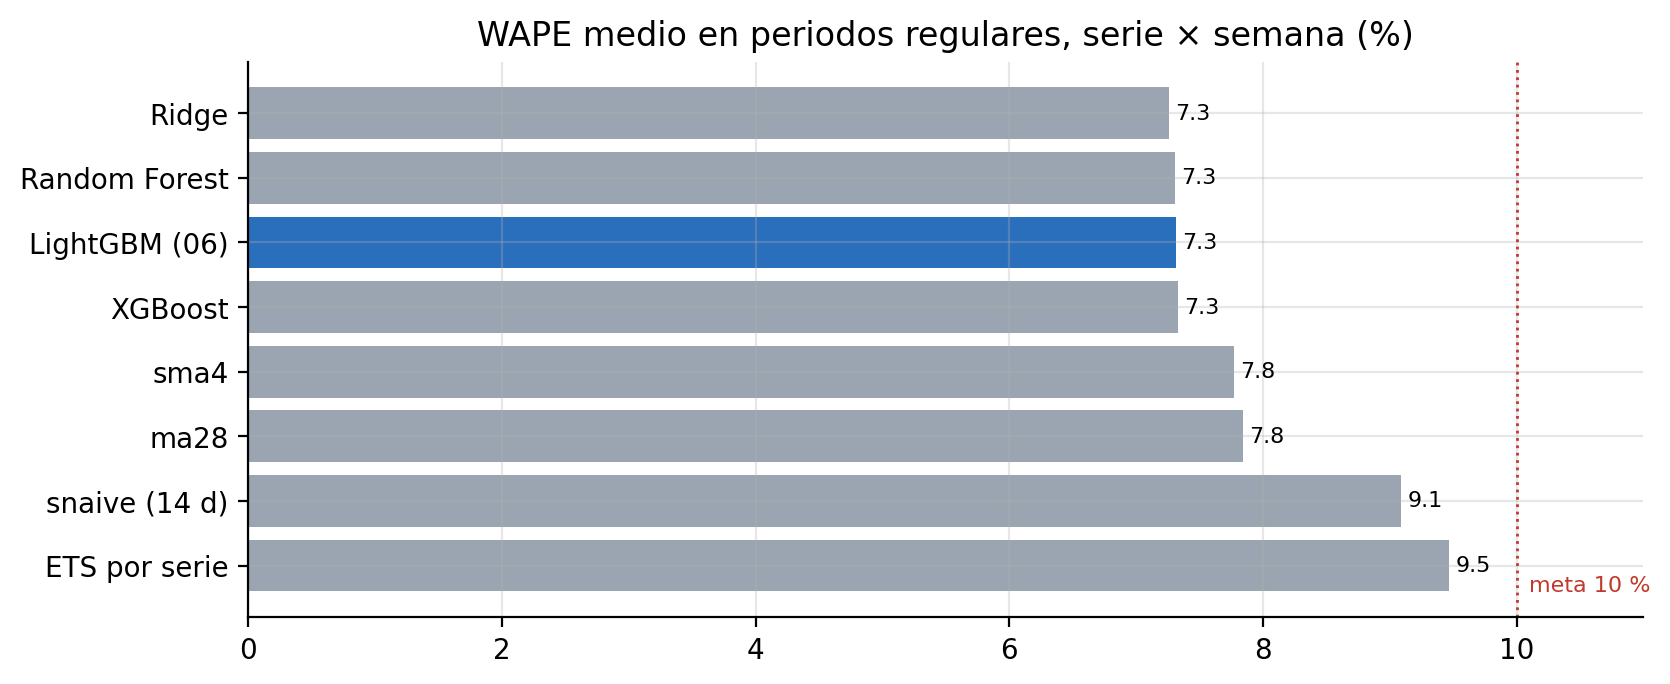

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.6)); r = R1.sort_values('WAPE %', ascending=False)
ax.barh(r.index, r['WAPE %'], color=['#2a6fbb' if i == 'LightGBM (06)' else '#9aa5b1' for i in r.index]); ax.axvline(10, color='#c0392b', ls=':', lw=1); ax.text(10.1, -0.4, 'meta 10 %', color='#c0392b', fontsize=8)
for i, v in enumerate(r['WAPE %']): ax.text(v + 0.05, i, f'{v:.1f}', va='center', fontsize=8)
ax.set(title='WAPE medio en periodos regulares, serie × semana (%)', xlim=(0, 11)); plt.show()

## 5. ¿Las diferencias son reales? Propuesta final contra cada competidor (regulares)

In [8]:
rg = P[P.kind == 'regular']; others = [k for k in MODELS if k != 'LightGBM (06)']
S = pd.DataFrame({k + ' + capa': compare(rg, 'pred_lgbm_r', MODELS[k] + '_r') for k in others}).T
S.columns = ['WAPE propuesta', 'WAPE competidor', 'Δ pts (propuesta − comp.)', 'IC95 inf', 'IC95 sup', 'p (bootstrap)', 'semanas', 'semanas propuesta mejor', 'p Wilcoxon']
pv = S['p (bootstrap)'].sort_values(); m_ = len(pv); adj = pd.Series(np.minimum(1, np.maximum.accumulate([(m_ - i) * v for i, v in enumerate(pv.values)])), index=pv.index)
S['p Holm'] = adj.reindex(S.index); S.sort_values('Δ pts (propuesta − comp.)').round(3)

,WAPE propuesta,WAPE competidor,Δ pts (propuesta − comp.),IC95 inf,IC95 sup,p (bootstrap),semanas,semanas propuesta mejor,p Wilcoxon,p Holm
ETS por serie + capa,7.34,9.59,-2.25,-2.89,-1.60,0.00,33.00,28.00,0.00,0.00
snaive (14 d) + capa,7.34,9.12,-1.78,-2.15,-1.41,0.00,33.00,32.00,0.00,0.00
ma28 + capa,7.34,7.89,-0.55,-0.87,-0.24,0.00,33.00,20.00,0.01,0.00
sma4 + capa,7.34,7.80,-0.46,-0.77,-0.19,0.00,33.00,20.00,0.01,0.00
XGBoost + capa,7.34,7.37,-0.03,-0.06,0.01,0.12,33.00,21.00,0.25,0.37
Random Forest + capa,7.34,7.33,0.01,-0.09,0.11,0.86,33.00,18.00,0.94,0.86
Ridge + capa,7.34,7.17,0.18,-0.05,0.40,0.13,33.00,7.00,0.00,0.37


**Lectura.**
- La propuesta supera con significancia a `sma4`, `ma28`, `snaive` y ETS (Δ de −0.46, −0.55, −1.78 y −2.25 pts; IC95 completamente bajo 0; p Holm < 0.01).
- Contra XGBoost y Random Forest no hay diferencia distinguible (Δ −0.03 con IC95 [−0.06, +0.01] y +0.01 con [−0.09, +0.11]).
- **Contra Ridge** el Δ es +0.18 pts (IC95 [−0.05, +0.40]). El bootstrap no excluye 0, pero Wilcoxon sí (p < 0.01): Ridge gana en 26 de las 33 semanas con márgenes pequeños y consistentes. K1, fijado sobre el IC, se cumple; pero no se puede afirmar que la propuesta sea mejor que Ridge en periodos regulares, y lo más probable es que Ridge sea ligeramente mejor.
- La tabla usa el WAPE agrupado de todas las semanas (7.34 %), por eso difiere un poco de la media por fold de 4.1 (7.31 %).

## 6. Por qué WAPE como métrica principal

**La decisión que sirve el pronóstico** es la reposición semanal por tienda y categoría. Eso fija el grano de evaluación (serie × semana) y pide una métrica que responda a «¿qué parte de lo vendido planeé mal?».

**Por qué WAPE (Σ|error| / Σ ventas):**
- **Pondera por volumen.** Una serie grande equivocada pesa más que una pequeña, igual que en pesos de inventario y de venta perdida.
- **Es comparable entre 480 series de tamaños muy distintos** (Express, Bodega, Supercenter) y se lee como porcentaje de venta mal planeada. La meta del reto (≈ 10 %) está definida así.
- **No se rompe con valores pequeños**: no divide fila por fila entre ventas cercanas a cero.
- **Es lineal en el error**: no exagera los pocos picos de evento (como hace RMSE) ni los ignora.

**Por qué no las otras (y se verifica empíricamente en 6.1–6.3):**
- **MAPE** da el mismo peso a cada fila, es inestable con ventas pequeñas y favorece pronosticar de menos (el error de subpronóstico está acotado en 100 % y el de sobrepronóstico no). En inventario eso esconde faltantes.
- **MAE y RMSE** dependen de la escala: se dominan por las series grandes y no se pueden comparar entre niveles de agregación. RMSE además se dispara con los picos de evento.
- **sMAPE** corrige la asimetría solo en parte y sigue sin ponderar por volumen.
- **R²** se infla con la diferencia de escala entre series (0.97 en el 06 incluso con baselines que pasaban el umbral) y no discrimina entre modelos.
- **MASE/RMSSE** exigen una escala de referencia dentro de la muestra por serie; el cociente WAPE del modelo / WAPE de `sma4` («habilidad») da la misma lectura sin ese costo.
- **Pinball y cobertura** son las métricas correctas para p10/p90; entrarán cuando se construyan los cuantiles.

**Qué acompaña a WAPE:** el **sesgo** (WAPE es simétrico y oculta si se sobre o subpronostica, que cuesta distinto en inventario), el WAPE por nivel de agregación (contra el piso de ruido del 06) y el **WAPE asimétrico** (subpronóstico pesa 2×) como prueba de robustez, porque no hay costos de negocio reales.

### 6.1 ¿Cambia el ranking según la métrica? (regulares y eventos, modelos sin capa)

In [9]:
met = ['wape', 'mape', 'smape', 'mae', 'rmse', 'sesgo', 'wape_asim']
def metric_means(folds): return pd.DataFrame({k: {m: grp(k, folds, m) for m in met} for k in MODELS}).T
for lab, fs in [('regulares', reg_f), ('eventos', ev_f)]:
    Mm = metric_means(fs); Mm['|sesgo|'] = Mm.sesgo.abs(); rk = Mm[['wape', 'mape', 'smape', 'mae', 'rmse', '|sesgo|', 'wape_asim']].rank()
    print(f'Valores medios ({lab}):'); display(Mm.round(2))
    print(f'Rango por métrica ({lab}; 1 = mejor) y correlación de Spearman con el rango por WAPE:'); display(rk.astype(int).T.assign(**{'Spearman con WAPE': [stats.spearmanr(rk.wape, rk[c_]).correlation for c_ in rk.columns]}).round(2))

Valores medios (regulares):


,wape,mape,smape,mae,rmse,sesgo,wape_asim,|sesgo|
sma4,7.77,7.71,7.76,"87,620.51","128,881.79",-1.60,12.45,1.60
snaive (14 d),9.09,9.05,9.07,"102,679.48","151,837.01",-0.86,14.07,0.86
ma28,7.84,7.77,7.84,"88,416.55","130,018.26",-1.86,12.70,1.86
ETS por serie,9.47,9.37,9.67,"106,472.91","152,800.28",-4.04,16.23,4.04
Ridge,7.26,7.23,7.20,"81,982.33","121,576.87",-0.54,11.16,0.54
Random Forest,7.31,7.31,7.24,"82,546.87","123,053.44",-0.27,11.09,0.27
XGBoost,7.33,7.28,7.23,"82,799.34","124,455.23",-0.37,11.18,0.37
LightGBM (06),7.31,7.26,7.21,"82,607.51","124,221.56",-0.35,11.14,0.35


Rango por métrica (regulares; 1 = mejor) y correlación de Spearman con el rango por WAPE:


,sma4,snaive (14 d),ma28,ETS por serie,Ridge,Random Forest,XGBoost,LightGBM (06),Spearman con WAPE
wape,5,7,6,8,1,2,4,3,1.00
mape,5,7,6,8,1,4,3,2,0.93
smape,5,7,6,8,1,4,3,2,0.93
mae,5,7,6,8,1,2,4,3,1.00
rmse,5,7,6,8,1,2,4,3,1.00
|sesgo|,6,5,7,8,4,1,3,2,0.79
wape_asim,5,7,6,8,3,1,4,2,0.93


Valores medios (eventos):


,wape,mape,smape,mae,rmse,sesgo,wape_asim,|sesgo|
sma4,23.01,23.64,24.14,"407,936.37","616,902.24",-11.92,40.47,11.92
snaive (14 d),27.81,30.18,28.08,"495,853.67","709,655.16",-10.01,46.72,10.01
ma28,22.18,22.50,23.65,"392,657.03","587,127.34",-13.67,40.10,13.67
ETS por serie,38.32,36.46,34.45,"674,589.66","1,021,968.36",-2.83,58.89,2.83
Ridge,35.30,35.64,36.36,"611,932.63","842,041.95",-8.36,57.13,8.36
Random Forest,29.25,29.77,29.95,"513,415.88","722,222.87",-8.68,48.22,8.68
XGBoost,24.33,24.21,25.60,"427,879.62","648,197.09",-15.54,44.26,15.54
LightGBM (06),25.36,25.10,27.19,"444,430.88","664,315.80",-17.34,46.70,17.34


Rango por métrica (eventos; 1 = mejor) y correlación de Spearman con el rango por WAPE:


,sma4,snaive (14 d),ma28,ETS por serie,Ridge,Random Forest,XGBoost,LightGBM (06),Spearman con WAPE
wape,2,5,1,8,7,6,3,4,1.00
mape,2,6,1,8,7,5,3,4,0.98
smape,2,5,1,7,8,6,3,4,0.98
mae,2,5,1,8,7,6,3,4,1.00
rmse,2,5,1,8,7,6,3,4,1.00
|sesgo|,5,4,6,1,2,3,7,8,-0.79
wape_asim,2,5,1,8,7,6,3,4,1.00


**Lectura.**
- **En este caso la métrica elegida no cambia el ranking.** En regulares, WAPE, MAE y RMSE dan el mismo orden (Spearman 1.00); MAPE, sMAPE y WAPE asimétrico solo intercambian posiciones entre los modelos empatados (LightGBM, XGBoost, Random Forest). En eventos, WAPE, MAE y RMSE vuelven a coincidir. La razón para preferir WAPE no es que cambie la conclusión: se interpreta como porcentaje de venta mal planeada, se compara entre niveles de agregación y no depende de la escala.
- **El sesgo por sí solo engaña.** En eventos ETS tiene el menor |sesgo| (2.8 %) y a la vez el peor WAPE (38.3 %): sus errores positivos y negativos se cancelan. El rango por |sesgo| se correlaciona −0.79 con el de WAPE. Por eso el sesgo se reporta junto a WAPE y no en su lugar.
- En eventos LightGBM (−17 %) y XGBoost (−16 %) subpronostican el pico: es el riesgo de faltante que los intervalos p10/p90 deben cubrir.

### 6.2 Prueba con modelos deliberadamente sesgados (LightGBM × factor)

In [10]:
rows = {}
for s in (0.90, 0.95, 1.00, 1.05, 1.10):
    A = A_sw[A_sw.kind == 'regular'].copy(); A['x'] = A.pred_lgbm * s; mf = metric_frame(A, ['x']); rows[f'× {s:.2f}'] = mf[met].mean()
pd.DataFrame(rows).T.round(2)

,wape,mape,smape,mae,rmse,sesgo,wape_asim
× 0.90,11.41,10.79,11.61,"128,367.00","183,470.11",-10.31,22.27
× 0.95,8.43,8.03,8.36,"94,860.19","142,335.24",-5.33,15.30
× 1.00,7.31,7.26,7.21,"82,607.51","124,221.56",-0.35,11.14
× 1.05,8.33,8.65,8.21,"94,469.44","137,160.74",4.64,10.18
× 1.10,11.15,11.78,10.87,"126,727.96","175,189.86",9.62,11.92


**Lectura.**
- Un LightGBM deliberadamente 10 % por debajo obtiene MAPE 10.8 %, menor que su WAPE (11.4 %); con 10 % por encima, MAPE 11.8 % (WAPE 11.2 %). **MAPE flatera el subpronóstico y castiga el sobrepronóstico**, porque el error de un subpronóstico está acotado en 100 % de la venta y el del sobrepronóstico no. WAPE trata ambos lados casi igual (11.4 y 11.2 %).
- Con un costo asimétrico (el subpronóstico pesa 2×) el mínimo se desplaza hacia arriba: el WAPE asimétrico es menor con × 1.05 (10.2) que con × 1.00 (11.1) y × 0.95 (15.3). No hay costos de negocio reales, así que no se ajusta el modelo en esa dirección, pero es el argumento para los cuantiles p10/p90.
- MAE y RMSE crecen con el sesgo sin distinguir su dirección.

### 6.3 WAPE por nivel de agregación (propuesta final contra `sma4`)

In [11]:
keys = {'serie × semana': ['store_id', 'category', 'semana'], 'tienda × semana': ['store_id', 'semana'], 'categoría × semana': ['category', 'semana'], 'total × semana': ['semana']}
floor = {'serie × día': 15.6, 'serie × semana': 6.5, 'tienda × semana': 3.4, 'categoría × semana': 2.1, 'total × semana': 2.1}
rows = {}
for l, k_ in keys.items():
    A = agg(k_); A = A[A.kind == 'regular']; mf = metric_frame(A, ['pred_lgbm_r', 'base_sma4_r', 'base_sma4']); w = mf.groupby('col').wape.mean()
    rows[l] = {'propuesta (LightGBM + capa)': w['pred_lgbm_r'], 'sma4': w['base_sma4'], 'piso de ruido (06, en muestra)': floor[l]}
A = D[D.kind == 'regular']; mf = metric_frame(A, ['pred_lgbm_r', 'base_sma4']); w = mf.groupby('col').wape.mean(); rows['serie × día'] = {'propuesta (LightGBM + capa)': w['pred_lgbm_r'], 'sma4': w['base_sma4'], 'piso de ruido (06, en muestra)': floor['serie × día']}
pd.DataFrame(rows).T.loc[list(floor)].round(1)

,propuesta (LightGBM + capa),sma4,"piso de ruido (06, en muestra)"
serie × día,16.60,19.10,15.60
serie × semana,7.30,7.80,6.50
tienda × semana,3.90,4.80,3.40
categoría × semana,2.60,4.00,2.10
total × semana,2.60,4.00,2.10


**Lectura.** La propuesta queda a 1.0 pt del piso de ruido en serie × día (16.6 % vs 15.6 %), a 0.8 pts en serie × semana (7.3 % vs 6.5 %) y a 0.5 pts en tienda × semana y en categoría × semana. La ventaja sobre `sma4` es de 2.5, 0.5, 0.9 y 1.4 pts en los niveles de serie × día, serie × semana, tienda × semana y categoría o total × semana. Se evalúa en serie × semana porque es el grano de la decisión de reposición y el más fino en que el piso de ruido (6.5 %) deja alcanzar la meta de 10 %; en serie × día el piso es 15.6 % y la métrica ya no discrimina.

## 7. Veredicto con los criterios fijados en la sección 2

In [12]:
fin = 'LightGBM (06) + capa'; comp = [k + ' + capa' for k in others]
gap = grp(fin, reg_f) - min(grp(c_, reg_f) for c_ in comp); best = min(comp, key=lambda c_: grp(c_, reg_f))
sig_worse = S[S['IC95 inf'] > 0].index.tolist(); sig_better = S[S['IC95 sup'] < 0].index.tolist(); tied = S[(S['IC95 inf'] <= 0) & (S['IC95 sup'] >= 0)].index.tolist()
post = {m: grp(m, ['post_navidad_2024']) for m in comp + [fin]}; rank_post = sorted(post, key=post.get).index(fin) + 1
V_ = pd.Series({'WAPE regulares propuesta (%)': grp(fin, reg_f), 'mejor competidor en regulares': best, 'WAPE del mejor competidor (%)': grp(best, reg_f), 'diferencia vs mejor (pts)': gap,
                'competidores que la superan con significancia': ', '.join(sig_worse) or 'ninguno', 'competidores a los que supera con significancia': ', '.join(sig_better) or 'ninguno',
                'empates técnicos (IC95 incluye 0)': ', '.join(tied) or 'ninguno', 'K1 (regulares)': 'cumple' if (gap <= 0.1 and not sig_worse) else 'NO cumple',
                'puesto en post-evento con capa (de %d)' % len(post): rank_post, 'K2 (post-evento)': 'cumple' if rank_post <= 2 else 'NO cumple'}); V_.to_frame('resultado')

,resultado
WAPE regulares propuesta (%),7.31
mejor competidor en regulares,Ridge + capa
WAPE del mejor competidor (%),7.25
diferencia vs mejor (pts),0.06
competidores que la superan con significancia,ninguno
competidores a los que supera con significancia,"sma4 + capa, snaive (14 d) + capa, ma28 + capa..."
empates técnicos (IC95 incluye 0),"Ridge + capa, Random Forest + capa, XGBoost + ..."
K1 (regulares),cumple
puesto en post-evento con capa (de 8),3
K2 (post-evento),NO cumple


In [13]:
if tied:
    base_names = [t_.replace(' + capa', '') for t_ in tied] + ['LightGBM (06)']
    sec = pd.DataFrame({k: {'WAPE regulares (%)': grp(k + ' + capa', reg_f), 'desv. estándar entre folds regulares (pts)': MF[(MF.modelo == k + ' + capa') & MF.fold.isin(reg_f)].wape.std(),
                            'tiempo de backtest (s)': TIMES.get({'ETS por serie': 'pred_ets', 'Ridge': 'pred_ridge', 'Random Forest': 'pred_rf', 'XGBoost': 'pred_xgb', 'LightGBM (06)': 'pred_lgbm'}.get(k) or '', np.nan)} for k in base_names}).T
    print('Criterios secundarios (K4) entre la propuesta y sus empates técnicos:'); display(sec.round(2))

Criterios secundarios (K4) entre la propuesta y sus empates técnicos:


,WAPE regulares (%),desv. estándar entre folds regulares (pts),tiempo de backtest (s)
Ridge,7.25,0.75,2.53
Random Forest,7.30,0.46,54.01
XGBoost,7.33,0.52,13.06
LightGBM (06),7.31,0.49,10.13


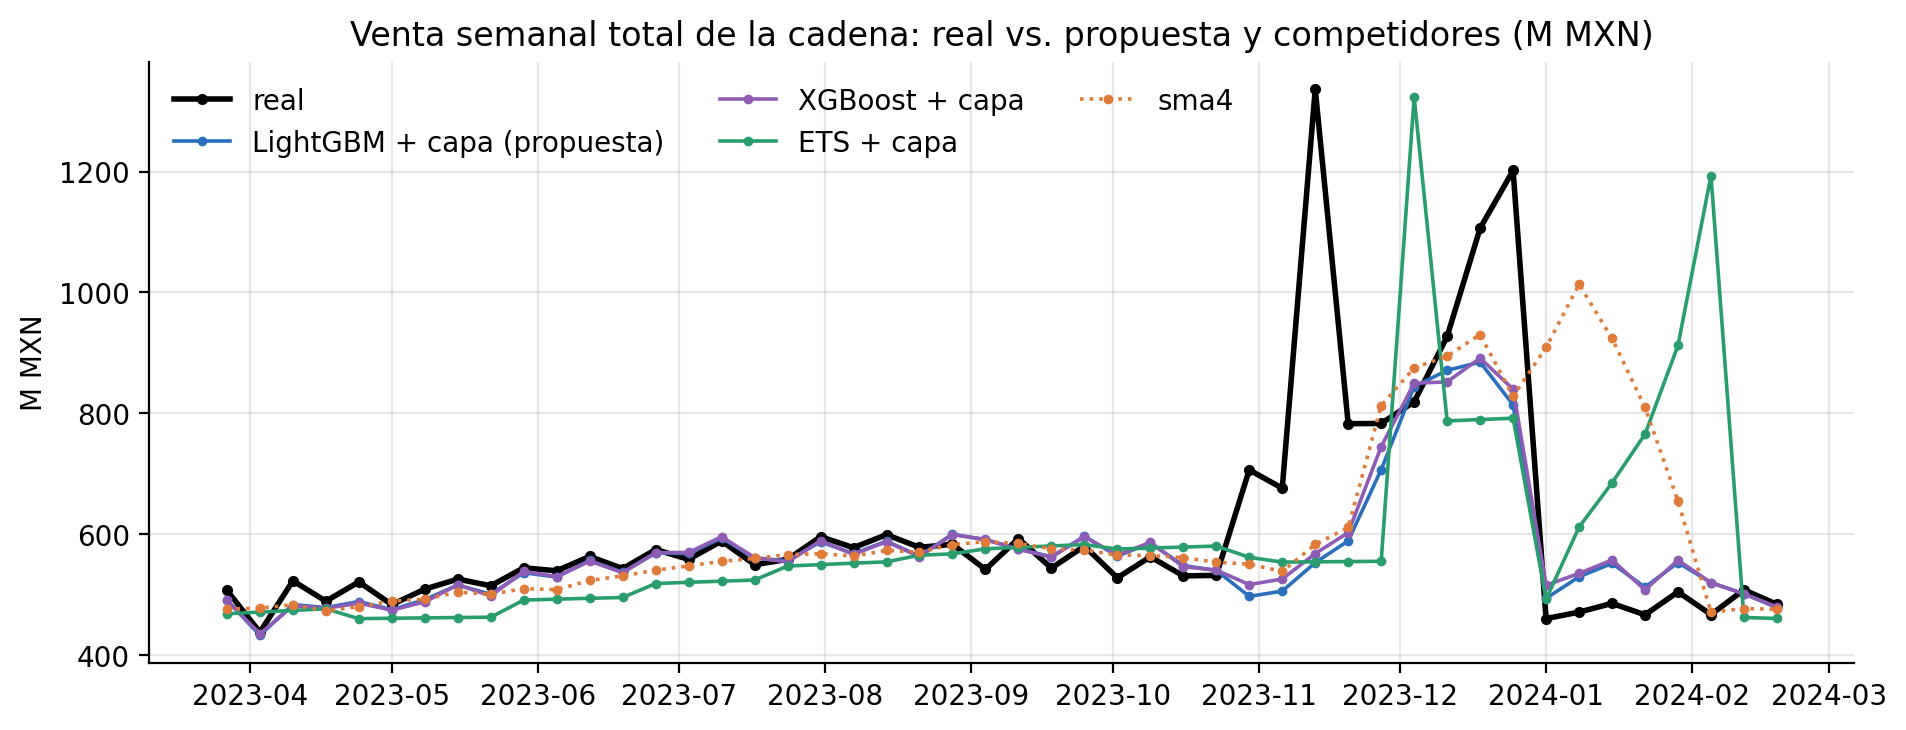

In [14]:
Wc = D.groupby('semana')[['y', 'pred_lgbm_r', 'pred_xgb_r', 'pred_ets_r', 'base_sma4']].sum().div(1e6)
fig, ax = plt.subplots(figsize=(11, 3.9)); ax.plot(Wc.index, Wc.y, 'k-o', ms=3, lw=2, label='real')
for c_, l_, col_ in [('pred_lgbm_r', 'LightGBM + capa (propuesta)', '#2a6fbb'), ('pred_xgb_r', 'XGBoost + capa', '#8e5bb5'), ('pred_ets_r', 'ETS + capa', '#2a9d6f'), ('base_sma4', 'sma4', '#e07b39')]:
    ax.plot(Wc.index, Wc[c_], color=col_, marker='o', ms=2.5, lw=1.3, ls=':' if c_ == 'base_sma4' else '-', label=l_)
ax.set(title='Venta semanal total de la cadena: real vs. propuesta y competidores (M MXN)', ylabel='M MXN'); ax.legend(frameon=False, ncol=3, loc='upper left'); plt.show()

**Lectura.**
- **K1 se cumple** (0.06 pts de diferencia con el mejor, Ridge; ningún competidor la supera con significancia según el IC95), con la salvedad de Wilcoxon contra Ridge (sección 5).
- **K2 no se cumple:** con la misma capa, la propuesta es 3ª de 8 en post-Navidad (12.8 %); `sma4 + capa` obtiene 11.7 % y Random Forest + capa 12.4 %.
- **K3 (solo reporte):** en eventos `ma28` y `sma4`, con y sin capa, superan a los modelos de ML.
- **K4:** hay empate técnico con Ridge, Random Forest y XGBoost. Ridge es el más rápido pero el menos estable entre folds (desviación 0.75 pts) y falla en las rampas (42.2 % en `pre_navidad_2023`, 35.3 % medio en eventos). Random Forest es unas 4 veces más lento que XGBoost y no aporta ventaja. XGBoost y LightGBM son equivalentes: se conserva LightGBM por continuidad con el protocolo, las ablaciones y el SHAP del 06, no por superioridad.

## 8. Conclusiones

1. **Propuesta final:** LightGBM del 06 + capa de reinicio de régimen (V1b, `src/models/regime.py`). Se conserva, pero con una afirmación más acotada que «es el mejor».
2. **Lo que sí se puede afirmar:** en periodos regulares supera con significancia a `sma4`, `ma28`, `snaive` y ETS (WAPE 7.3 % contra 7.8 %, 7.8 %, 9.1 % y 9.5 %), y es más robusto que Ridge y ETS en las semanas de rampa.
3. **Lo que no se puede afirmar:** que sea mejor que XGBoost, Random Forest o Ridge en regulares (empate técnico; Ridge gana en 26 de 33 semanas con márgenes pequeños), ni que supere a un baseline limpio en eventos y post-evento (`sma4 + capa` queda 1.1 pts mejor en post-Navidad y `ma28`/`sma4` ganan en eventos). K1 se cumple y K2 no.
4. **Métrica:** WAPE en serie × semana, con sesgo al lado. En estos datos MAE y RMSE darían el mismo ranking, así que la elección se justifica por interpretación (porcentaje de venta mal planeada), comparabilidad entre niveles y falta de escala. MAPE queda descartada porque flatera el subpronóstico (comprobado con modelos sesgados a propósito) y el sesgo solo engaña (ETS en eventos).
5. **Pendiente, si hay tiempo:** (a) cuantiles p10/p90, que además cubrirían el sesgo negativo en eventos (−16 % a −17 %); (b) un ensamble Ridge + LightGBM, dado que Ridge gana la mayoría de las semanas regulares; (c) evaluar una política híbrida (baseline limpio con alerta en ventanas de evento y ML fuera de ellas). Esta última solo se puede juzgar con la segunda ocurrencia de los eventos, porque con una sola no se debe seleccionar con ella.